# HR Employee Attrition Analysis

**Author:** Aneesh Dixit

**Business question:** About 1 in 6 employees in this company left. *Who* is leaving, *why*, and what can HR do about it?

**Dataset:** IBM HR Analytics Employee Attrition & Performance (Kaggle). 1,470 employees and 35 columns. It is a fictional dataset created by IBM data scientists.

**Contents**
1. Setup and data loading
2. Data quality check
3. Cleaning and feature engineering
4. Overall attrition
5. Overtime
6. Job role and department
7. Age and tenure
8. Income
9. Satisfaction and work-life balance
10. Travel and marital status
11. The highest-risk group
12. Business impact
13. Recommendations
14. Export to Excel

## 1. Setup and data loading

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Works whether the notebook is opened from the project folder or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from prepare_data import attrition_by, clean, load_raw

IMAGES = ROOT / "images"
IMAGES.mkdir(exist_ok=True)

# One consistent chart style for the whole project
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
})
NAVY, RED, GREY = "#1F3864", "#C00000", "#A6A6A6"

raw = load_raw()
print(f"Rows: {raw.shape[0]:,}   Columns: {raw.shape[1]}")
raw.head()

Rows: 1,470   Columns: 35


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 2. Data quality check
Before any analysis, check for missing values, duplicate rows, and columns that never change.

In [2]:
print("Missing values:", raw.isna().sum().sum())
print("Duplicate rows:", raw.duplicated().sum())
print("Duplicate employee IDs:", raw["EmployeeNumber"].duplicated().sum())

constant_cols = raw.columns[raw.nunique() == 1].tolist()
print("Columns with a single value:", constant_cols)

Missing values: 0
Duplicate rows: 0
Duplicate employee IDs: 0
Columns with a single value: ['EmployeeCount', 'Over18', 'StandardHours']


**Result:** the data is complete, with no missing values and no duplicates. Three columns (`EmployeeCount`, `Over18`, `StandardHours`) have the same value for every employee, so they carry no information and get dropped.

## 3. Cleaning and feature engineering
The cleaning steps live in `src/prepare_data.py`, so the notebook and the Excel dashboard use exactly the same data. The function:
- drops the three constant columns
- adds `AttritionFlag` (1 = left, 0 = stayed). The average of this flag is the attrition rate.
- turns survey codes (1–4) into labels such as *Low / Medium / High / Very High*
- groups age, tenure, and income into bands that are easy to compare

In [3]:
df = clean(raw)
df[["Age", "AgeBand", "YearsAtCompany", "TenureBand", "MonthlyIncome", "IncomeBand",
    "JobSatisfaction", "JobSatisfactionLabel", "Attrition", "AttritionFlag"]].head()

,Age,AgeBand,YearsAtCompany,TenureBand,MonthlyIncome,IncomeBand,JobSatisfaction,JobSatisfactionLabel,Attrition,AttritionFlag
0,41,36-45,6,6-10 yrs,5993,Q3,4,Very High,Yes,1
1,49,46-60,10,6-10 yrs,5130,Q3,2,Medium,No,0
2,37,36-45,0,0-2 yrs,2090,Q1 (Lowest),3,High,Yes,1
3,33,26-35,8,6-10 yrs,2909,Q1 (Lowest),3,High,No,0
4,27,26-35,2,0-2 yrs,3468,Q2,2,Medium,No,0


In [4]:
def plot_rate(summary, title, filename, ax=None, highlight_top=1):
    """Horizontal bar chart of attrition rate, with the riskiest group(s) highlighted in red."""
    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(7, 0.45 * len(summary) + 1.2))
    rates = summary["AttritionRate"]
    colors = [RED if i < highlight_top else NAVY for i in range(len(rates))]
    ax.barh(rates.index.astype(str), rates.values, color=colors)
    ax.invert_yaxis()
    ax.axvline(OVERALL_RATE, color=GREY, linestyle="--", linewidth=1)
    for y, v in enumerate(rates.values):
        ax.text(v + 0.005, y, f"{v:.1%}", va="center", fontsize=9)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_title(title)
    ax.set_xlim(0, max(rates.max() * 1.2, OVERALL_RATE * 1.3))
    if own_fig:
        plt.tight_layout()
        plt.savefig(IMAGES / filename, bbox_inches="tight")
        plt.show()

## 4. Overall attrition

In [5]:
OVERALL_RATE = df["AttritionFlag"].mean()
leavers = df["AttritionFlag"].sum()
print(f"{leavers} of {len(df):,} employees left the company. Attrition rate = {OVERALL_RATE:.1%}")

237 of 1,470 employees left the company. Attrition rate = 16.1%


**16.1% of employees left.** That's roughly 1 in every 6 people, and it's the benchmark every group below is compared against (the grey dashed line on each chart below).

## 5. Overtime

,Employees,Left,AttritionRate
OverTime,,,
Yes,416,127,0.305
No,1054,110,0.104


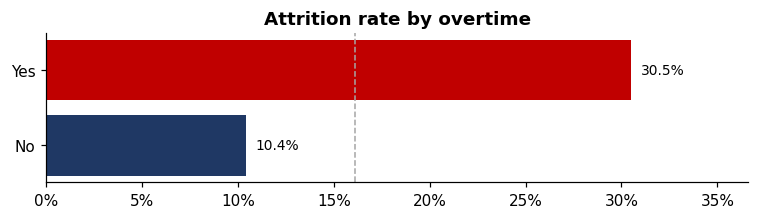

In [6]:
overtime = attrition_by(df, "OverTime")
display(overtime)
plot_rate(overtime, "Attrition rate by overtime", "01_overtime.png")

**Finding:** employees who work overtime leave at **30.5%**, about **3× the rate** of those who don't (10.4%). This is the single clearest driver in the data.

## 6. Job role and department

,Employees,Left,AttritionRate
JobRole,,,
Sales Representative,83,33,0.398
Laboratory Technician,259,62,0.239
Human Resources,52,12,0.231
Sales Executive,326,57,0.175
Research Scientist,292,47,0.161
Manufacturing Director,145,10,0.069
Healthcare Representative,131,9,0.069
Manager,102,5,0.049
Research Director,80,2,0.025


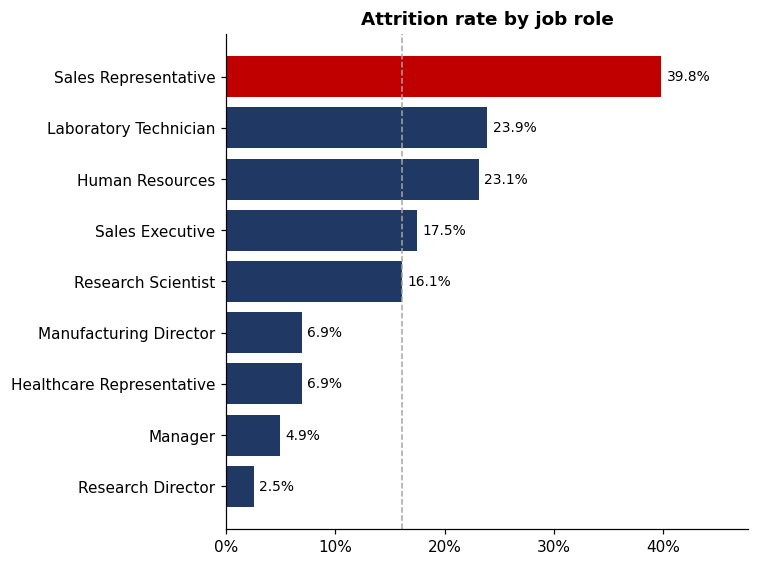

In [7]:
roles = attrition_by(df, "JobRole")
display(roles)
plot_rate(roles, "Attrition rate by job role", "02_job_role.png")

In [8]:
attrition_by(df, "Department")

,Employees,Left,AttritionRate
Department,,,
Sales,446,92,0.206
Human Resources,63,12,0.190
Research & Development,961,133,0.138


**Finding:** **Sales Representatives** leave at **39.8%**, the highest of any role and about 2.5× the company average. **Laboratory Technicians** (23.9%) and **HR** staff (23.1%) are also well above average. Senior roles (Managers 4.9%, Research Directors 2.5%) almost never leave. At the department level, Sales (20.6%) is the highest.

## 7. Age and tenure

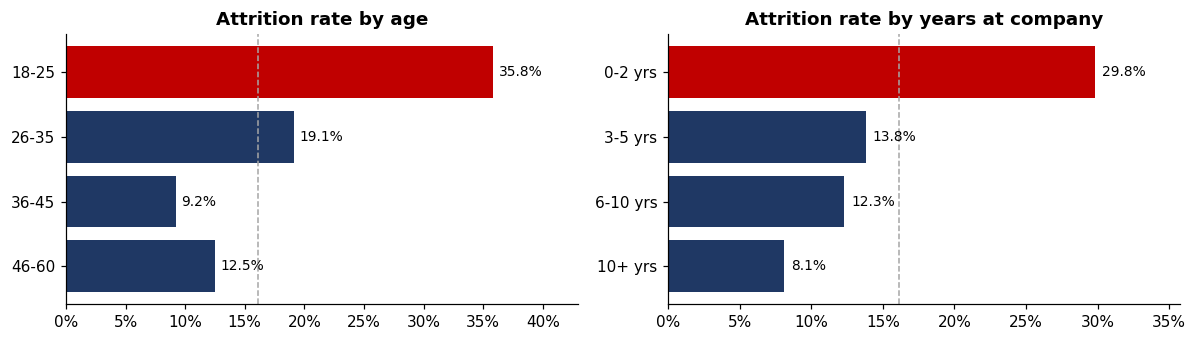

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
age_order = ["18-25", "26-35", "36-45", "46-60"]
tenure_order = ["0-2 yrs", "3-5 yrs", "6-10 yrs", "10+ yrs"]
plot_rate(attrition_by(df, "AgeBand").reindex(age_order), "Attrition rate by age", None, ax=axes[0])
plot_rate(attrition_by(df, "TenureBand").reindex(tenure_order), "Attrition rate by years at company", None, ax=axes[1])
plt.tight_layout()
plt.savefig(IMAGES / "03_age_tenure.png", bbox_inches="tight")
plt.show()

**Finding:** young employees aged **18–25 leave at 35.8%**, and people in their **first 2 years leave at 29.8%**. Attrition falls steadily as age and tenure grow. Most leaving happens early in an employee's time at the company.

## 8. Income

,Employees,Left,AttritionRate
IncomeBand,,,
Q1 (Lowest),369,108,0.293
Q2,366,52,0.142
Q3,367,39,0.106
Q4 (Highest),368,38,0.103


,min,max
IncomeBand,,
Q1 (Lowest),1009,2911
Q2,2926,4908
Q3,4930,8376
Q4 (Highest),8380,19999


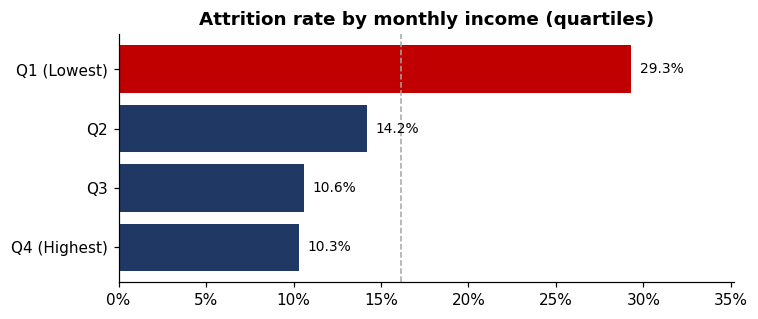

Attrition
No     5204.0
Yes    3202.0
Name: Median monthly income, dtype: float64


In [10]:
income_order = ["Q1 (Lowest)", "Q2", "Q3", "Q4 (Highest)"]
income = attrition_by(df, "IncomeBand").reindex(income_order)
display(income)
display(df.groupby("IncomeBand")["MonthlyIncome"].agg(["min", "max"]).reindex(income_order))
plot_rate(income, "Attrition rate by monthly income (quartiles)", "04_income.png")

print(df.groupby("Attrition")["MonthlyIncome"].median().rename("Median monthly income"))

**Finding:** the lowest-paid quarter of employees (monthly income below ~2,900) leaves at **29.3%**, almost 3× the rate of the top quarter (10.3%). The median income of leavers (3,202) is about **38% lower** than that of employees who stayed (5,204).

## 9. Satisfaction and work-life balance

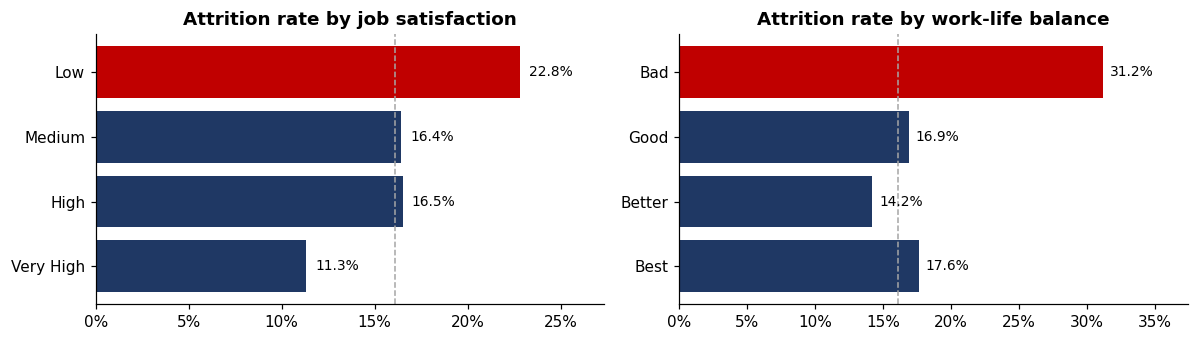

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
plot_rate(attrition_by(df, "JobSatisfactionLabel").reindex(["Low", "Medium", "High", "Very High"]),
          "Attrition rate by job satisfaction", None, ax=axes[0])
plot_rate(attrition_by(df, "WorkLifeBalanceLabel").reindex(["Bad", "Good", "Better", "Best"]),
          "Attrition rate by work-life balance", None, ax=axes[1])
plt.tight_layout()
plt.savefig(IMAGES / "05_satisfaction_wlb.png", bbox_inches="tight")
plt.show()

**Finding:** employees who rate their work-life balance as **Bad** leave at **31.2%**, and those with **Low** job satisfaction leave at **22.8%**. These survey scores can work as an early-warning signal for HR.

## 10. Travel and marital status

In [12]:
display(attrition_by(df, "BusinessTravel"))
display(attrition_by(df, "MaritalStatus"))

,Employees,Left,AttritionRate
BusinessTravel,,,
Travel Frequently,277,69,0.249
Travel Rarely,1043,156,0.150
Non-Travel,150,12,0.080


,Employees,Left,AttritionRate
MaritalStatus,,,
Single,470,120,0.255
Married,673,84,0.125
Divorced,327,33,0.101


**Finding:** frequent travellers leave at **24.9%**, versus 8.0% for non-travellers. **Single** employees leave at **25.5%**, about twice the rate of married (12.5%) or divorced (10.1%) employees. Single employees also tend to be younger, so this overlaps with the age finding above.

## 11. The highest-risk group
Overtime and job level are both strong signals. What happens when they combine?

OverTime,No overtime,Overtime
JobLevel,,
1,15.8%,52.6%
2,6.7%,17.8%
3,12.3%,20.6%
4,2.7%,9.1%
5,3.9%,16.7%


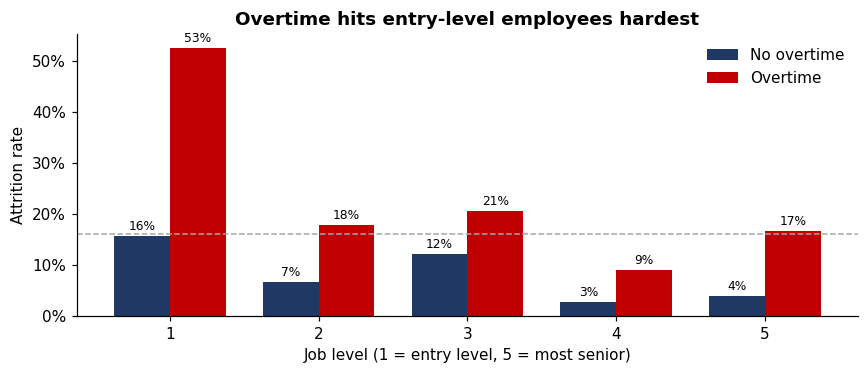

Entry-level employees working overtime: 156 people, 82 left, attrition rate 52.6%


In [13]:
segment = (
    df.pivot_table(index="JobLevel", columns="OverTime", values="AttritionFlag", aggfunc="mean")
    .rename(columns={"No": "No overtime", "Yes": "Overtime"})
)
display(segment.style.format("{:.1%}").background_gradient(cmap="Reds", axis=None))

ax = segment.plot(kind="bar", figsize=(8, 3.5), color=[NAVY, RED], rot=0, width=0.75)
ax.axhline(OVERALL_RATE, color=GREY, linestyle="--", linewidth=1)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Job level (1 = entry level, 5 = most senior)")
ax.set_ylabel("Attrition rate")
ax.set_title("Overtime hits entry-level employees hardest")
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:.0%}" for v in container.datavalues], fontsize=8, padding=2)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(IMAGES / "06_overtime_by_level.png", bbox_inches="tight")
plt.show()

risk = df[(df["JobLevel"] == 1) & (df["OverTime"] == "Yes")]
print(f"Entry-level employees working overtime: {len(risk)} people, "
      f"{risk['AttritionFlag'].sum()} left, attrition rate {risk['AttritionFlag'].mean():.1%}")

**Finding:** **entry-level (Job Level 1) employees who work overtime leave at 52.6%.** More than half of this group of 156 people left. That's over 3× the company average, which makes it the clearest group for HR to focus on.

## 12. Business impact
A simple *what-if*: suppose overtime workers left at the same rate as everyone else.

In [14]:
ot = df[df["OverTime"] == "Yes"]
no_ot_rate = df.loc[df["OverTime"] == "No", "AttritionFlag"].mean()
expected = len(ot) * no_ot_rate
avoided = ot["AttritionFlag"].sum() - expected

print(f"Overtime workers who left:        {ot['AttritionFlag'].sum()}")
print(f"Expected at the non-overtime rate: {expected:.0f}")
print(f"Potential leavers avoided:         {avoided:.0f}  "
      f"({avoided / df['AttritionFlag'].sum():.0%} of all attrition)")

Overtime workers who left:        127
Expected at the non-overtime rate: 43
Potential leavers avoided:         84  (35% of all attrition)


**Impact:** if overtime workers left at the same rate as everyone else, about **84 fewer people** would have left. That's roughly **35% of all attrition**. This is a simple comparison, not proof of cause and effect, but it shows how big the overtime issue is.

## 13. Recommendations

| # | Recommendation | Supported by |
|---|---|---|
| 1 | **Control overtime**, especially for entry-level staff. Track overtime hours per team and set limits or rotate workload. | Overtime 30.5% vs 10.4%; Level 1 + overtime 52.6% |
| 2 | **Review Sales Representative pay and targets**, and run exit interviews for this role. | Sales Reps 39.8% |
| 3 | **Strengthen the first two years**: structured onboarding, mentors, and check-ins at 3, 6, and 12 months. | 0–2 yrs tenure 29.8%; age 18–25 35.8% |
| 4 | **Benchmark salaries for the lowest pay band** and give a clear path to the next job level. | Lowest income quartile 29.3% |
| 5 | **Use survey scores as an early warning**: follow up with anyone reporting Low satisfaction or Bad work-life balance. | Bad WLB 31.2%; Low job satisfaction 22.8% |

**Limitations:** this is a fictional dataset, and the analysis compares groups. It shows *patterns*, not *causes*. Some factors overlap. For example, younger employees are also more likely to be single, entry-level, and lower paid.

## 14. Export to Excel
Save the cleaned data and build the Excel dashboard (`outputs/HR_Attrition_Dashboard.xlsx`).

In [15]:
from build_excel_dashboard import build

df.to_csv(ROOT / "data" / "hr_attrition_clean.csv", index=False)
dashboard_path = build()
print("Saved:", dashboard_path.relative_to(ROOT))

Saved: outputs/HR_Attrition_Dashboard.xlsx
